In [1]:
import pandas as pd

HITRAN_data = pd.read_csv('../data/CO2Min.txt', usecols=[0, 1, 2], header=0)
print(HITRAN_data.head(6))
print(len(HITRAN_data))   

           nu            sw  gamma_air
0  570.047412  2.324000e-29   0.073667
1  570.081920  2.985000e-30   0.055198
2  570.088032  2.017000e-30   0.069902
3  570.126984  5.468000e-28   0.070941
4  570.130811  6.859000e-28   0.064243
5  570.194609  1.522000e-29   0.058263
19303


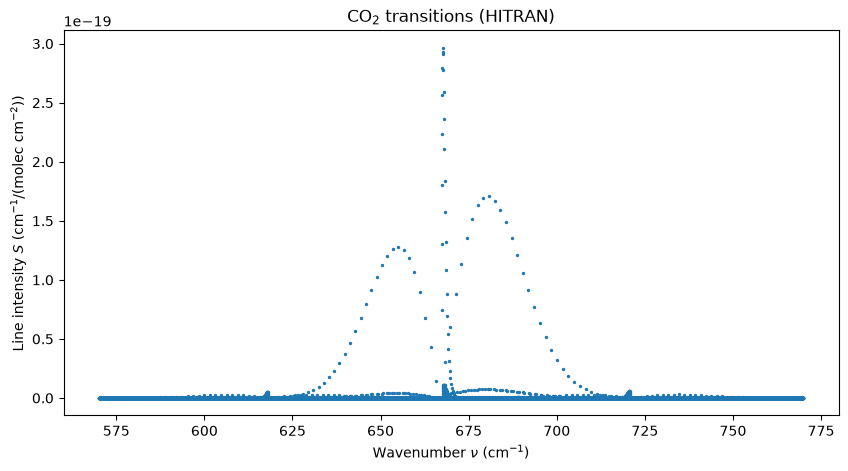

In [2]:
import matplotlib.pyplot as plt

nu = HITRAN_data.iloc[:, 0]   # wavenumber, cm^-1
S  = HITRAN_data.iloc[:, 1]   # line intensity, cm^-1/(molec·cm^-2)

plt.figure(figsize=(10, 5))
plt.scatter(nu, S, s=2)
plt.xlabel(r'Wavenumber $\nu$ (cm$^{-1}$)')
plt.ylabel(r'Line intensity $S$ (cm$^{-1}$/(molec cm$^{-2}$))')
plt.title(r'CO$_2$ transitions (HITRAN)')
plt.show()

In [3]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from greenhouse_spectra.planck import planck_nu, planck_lambda

In [4]:
import pandas as pd

e490 = pd.read_excel('../data/e490_00a_amo.xls')
print(e490.head())
print(e490.columns)

   Wavelength, microns  E-490 W/m2/micron  Unnamed: 2  Unnamed: 3  Unnamed: 4  \
0               0.1195             0.0619         NaN         NaN         NaN   
1               0.1205             0.5614         NaN         NaN         NaN   
2               0.1215             4.9010         NaN         NaN         NaN   
3               0.1225             1.1840         NaN         NaN         NaN   
4               0.1235             0.0477         NaN         NaN         NaN   

   Unnamed: 5  Unnamed: 6  Unnamed: 7  Unnamed: 8  Unnamed: 9  Unnamed: 10  \
0         NaN         NaN         NaN         NaN         NaN          NaN   
1         NaN         NaN         NaN         NaN         NaN          NaN   
2         NaN         NaN         NaN         NaN         NaN          NaN   
3         NaN         NaN         NaN         NaN         NaN          NaN   
4         NaN         NaN         NaN         NaN         NaN          NaN   

   Unnamed: 11  Unnamed: 12  Wavelength, nm 

Incoming, Planck :  1361.1 W/m^2
Incoming, E490   :  1366.1 W/m^2
Outgoing, Planck :   238.2 W/m^2  (at T_E = 254.6 K)
Absorbed (1-a)S0/4 = 238.2 W/m^2


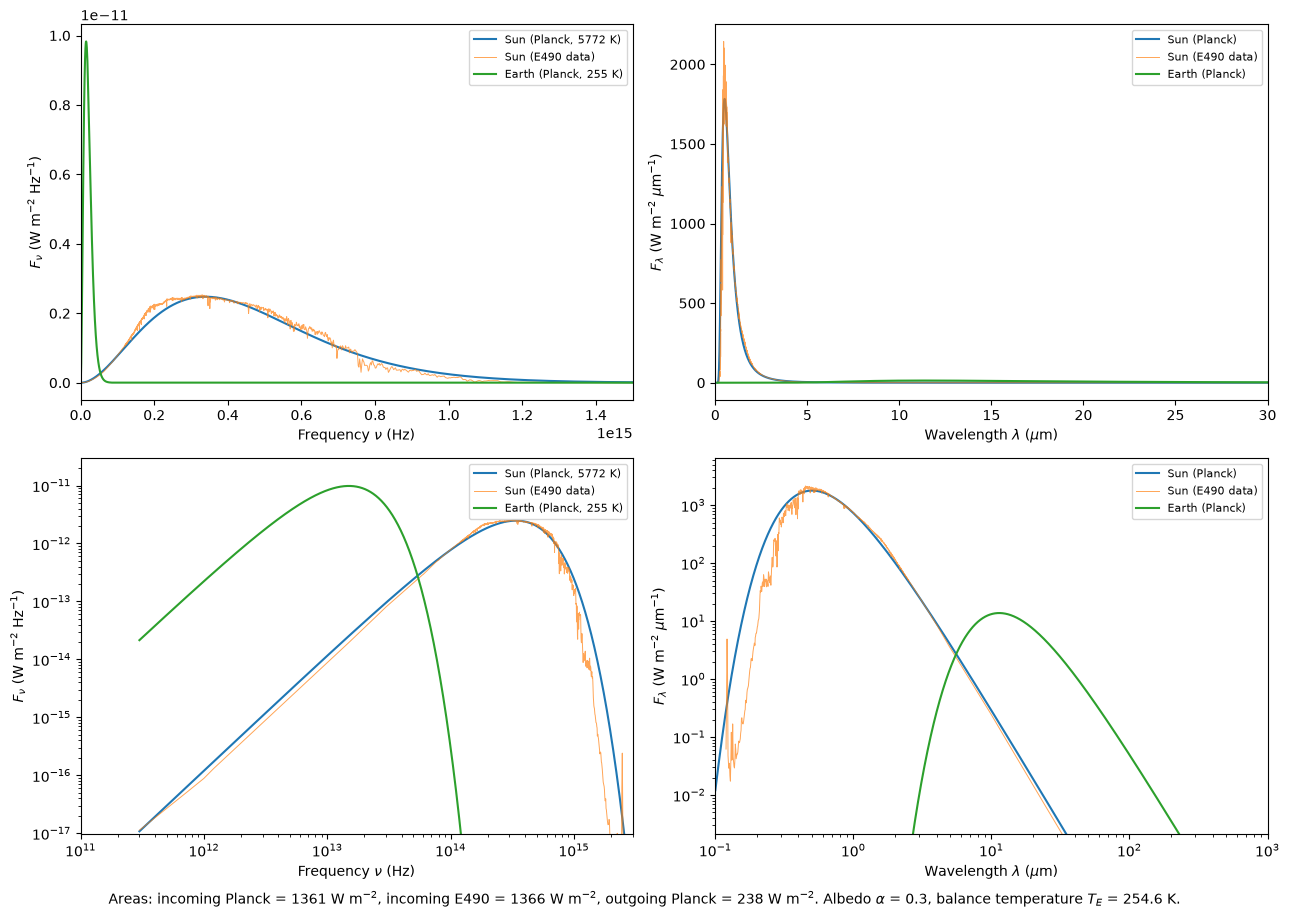

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import c

from greenhouse_spectra.constants import ALBEDO, T_SUN
from greenhouse_spectra.energy_balance import (
    solar_irradiance_nu, solar_irradiance_lambda,
    earth_emission_nu, earth_emission_lambda,
    integrate, absorbed_flux, balance_temperature,
)

# Grids
lam = np.logspace(-7, -3, 6000)          # 0.1 µm – 1000 µm, in m
nu  = c / lam                            # Hz

# E490 data (µm, W m^-2 µm^-1) -> SI
e490   = pd.read_excel('../data/e490_00a_amo.xls')
lam_e  = e490.iloc[:, 0].to_numpy() * 1e-6       # m
Flam_e = e490.iloc[:, 1].to_numpy() * 1e6        # W m^-2 m^-1
nu_e   = c / lam_e
Fnu_e  = Flam_e * lam_e**2 / c                   # W m^-2 Hz^-1

# Areas under the curves and energy balance
S0_planck = integrate(solar_irradiance_nu(nu), nu)
S0_e490   = integrate(Flam_e, lam_e)
outgoing  = lambda T: integrate(earth_emission_nu(nu, T), nu)
T_E       = balance_temperature(S0_planck, ALBEDO, outgoing)
S_out     = outgoing(T_E)

print(f'Incoming, Planck : {S0_planck:7.1f} W/m^2')
print(f'Incoming, E490   : {S0_e490:7.1f} W/m^2')
print(f'Outgoing, Planck : {S_out:7.1f} W/m^2  (at T_E = {T_E:.1f} K)')
print(f'Absorbed (1-a)S0/4 = {absorbed_flux(S0_planck, ALBEDO):.1f} W/m^2')

# 4-panel plot
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

for row, scale in enumerate(['linear', 'log']):
    # Frequency column
    a = ax[row, 0]
    a.plot(nu,   solar_irradiance_nu(nu),        label=fr'Sun (Planck, {T_SUN:.0f} K)')
    a.plot(nu_e, Fnu_e, lw=0.7, alpha=0.7,       label='Sun (E490 data)')
    a.plot(nu,   earth_emission_nu(nu, T_E),     label=fr'Earth (Planck, {T_E:.0f} K)')
    a.set_xlabel(r'Frequency $\nu$ (Hz)')
    a.set_ylabel(r'$F_\nu$ (W m$^{-2}$ Hz$^{-1}$)')

    # Wavelength column (per µm for readable numbers)
    a = ax[row, 1]
    a.plot(lam * 1e6,   solar_irradiance_lambda(lam) * 1e-6,    label='Sun (Planck)')
    a.plot(lam_e * 1e6, Flam_e * 1e-6, lw=0.7, alpha=0.7,       label='Sun (E490 data)')
    a.plot(lam * 1e6,   earth_emission_lambda(lam, T_E) * 1e-6, label='Earth (Planck)')
    a.set_xlabel(r'Wavelength $\lambda$ ($\mu$m)')
    a.set_ylabel(r'$F_\lambda$ (W m$^{-2}$ $\mu$m$^{-1}$)')

    for a in ax[row]:
        a.set_xscale(scale)
        a.set_yscale(scale)

ax[0, 0].set_xlim(0, 1.5e15)
ax[0, 1].set_xlim(0, 30)
for a in ax[1]:
    top = max(l.get_ydata().max() for l in a.get_lines())
    a.set_ylim(top * 1e-6, top * 3)
ax[1, 0].set_xlim(1e11, 3e15)
ax[1, 1].set_xlim(0.1, 1000)
for a in ax.flat:
    a.legend(fontsize=8)

caption = (f'Areas: incoming Planck = {S0_planck:.0f} W m$^{{-2}}$, '
           f'incoming E490 = {S0_e490:.0f} W m$^{{-2}}$, '
           f'outgoing Planck = {S_out:.0f} W m$^{{-2}}$. '
           fr'Albedo $\alpha$ = {ALBEDO}, balance temperature $T_E$ = {T_E:.1f} K.')
fig.text(0.5, -0.01, caption, ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('../figures/deliverable1_4panel.png', dpi=200, bbox_inches='tight')
plt.show()

Effective cross-section: sigma0 = 2.30e-19 cm^2, delta = 12.6 cm^-1


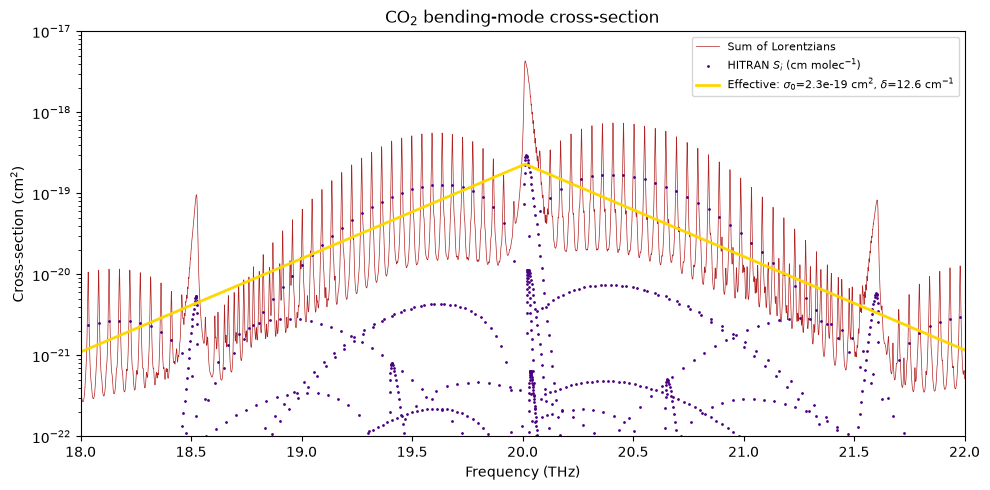

In [6]:
from greenhouse_spectra.co2 import (
    load_hitran, lorentzian_cross_section,
    fit_effective_cross_section, effective_cross_section,
)

lines = load_hitran('../data/CO2Min.txt')
nu_i, S_i, gam_i = (lines[col].to_numpy() for col in ['nu', 'sw', 'gamma_air'])

# Fine grid (lines are ~0.07 cm^-1 wide), surface pressure 1 atm -> gamma = gamma_air
wn = np.arange(nu_i.min() - 5, nu_i.max() + 5, 0.01)       # cm^-1
sigma_full = lorentzian_cross_section(wn, nu_i, S_i, gam_i * 1.0)

sigma0, delta = fit_effective_cross_section(wn, sigma_full, stat='mean')
sigma_eff = effective_cross_section(wn, sigma0, delta)
print(f'Effective cross-section: sigma0 = {sigma0:.2e} cm^2, delta = {delta:.1f} cm^-1')

to_THz = lambda w: 100 * c * w / 1e12

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(to_THz(wn), sigma_full, color='firebrick', lw=0.5, label='Sum of Lorentzians')
ax.plot(to_THz(nu_i), S_i, '.', color='indigo', ms=2, label=r'HITRAN $S_i$ (cm molec$^{-1}$)')
ax.plot(to_THz(wn), sigma_eff, color='gold', lw=2,
        label=fr'Effective: $\sigma_0$={sigma0:.1e} cm$^2$, $\delta$={delta:.1f} cm$^{{-1}}$')
ax.set_yscale('log')
ax.set_xlim(18, 22)
ax.set_ylim(1e-22, 1e-17)
ax.set_xlabel('Frequency (THz)')
ax.set_ylabel(r'Cross-section (cm$^2$)')
ax.set_title(r'CO$_2$ bending-mode cross-section')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('../figures/co2_cross_section.png', dpi=200)
plt.show()

In [7]:
from greenhouse_spectra.constants import X_CO2
from greenhouse_spectra.atmosphere import (
    outgoing_flux, outgoing_radiance, tropopause_temperature, column_density, wn_to_hz,
)

print(f'CO2 column N0 z0 = {column_density(X_CO2):.2e} cm^-2')
print(f'Peak optical depth (effective sigma) = {column_density(X_CO2) * sigma0:.0f}')

def solve_Ts(sig, x_gas=X_CO2):
    return balance_temperature(S0_planck, ALBEDO,
                               lambda T: outgoing_flux(T, wn, sig, x_gas),
                               bracket=(200, 350))

Ts_none = balance_temperature(S0_planck, ALBEDO)
Ts_eff  = solve_Ts(sigma_eff)
Ts_full = solve_Ts(sigma_full)
Ts_2x   = solve_Ts(sigma_full, 2 * X_CO2)

print(f'No CO2               : Ts = {Ts_none:.1f} K')
print(f'CO2, effective sigma : Ts = {Ts_eff:.1f} K  (T_trop = {tropopause_temperature(Ts_eff):.1f} K)')
print(f'CO2, full Lorentzian : Ts = {Ts_full:.1f} K  (T_trop = {tropopause_temperature(Ts_full):.1f} K)')
print(f'Doubled CO2 (full)   : Ts = {Ts_2x:.1f} K  ->  dT = {Ts_2x - Ts_full:+.2f} K')

CO2 column N0 z0 = 9.02e+21 cm^-2
Peak optical depth (effective sigma) = 2078
No CO2               : Ts = 254.6 K
CO2, effective sigma : Ts = 265.4 K  (T_trop = 195.5 K)
CO2, full Lorentzian : Ts = 264.9 K  (T_trop = 195.1 K)
Doubled CO2 (full)   : Ts = 265.4 K  ->  dT = +0.55 K


In [ ]:
from greenhouse_spectra.planck import planck_nu

# Coarse grid outside the band, fine grid inside
wn_plot  = np.concatenate([np.linspace(1, wn.min(), 800), wn, np.linspace(wn.max(), 2000, 1500)])
sig_plot = np.concatenate([np.zeros(800), sigma_full, np.zeros(1500)])
sig_eff_plot = effective_cross_section(wn_plot, sigma0, delta)

Ts = Ts_full
per_wn = 100 * c        # converts per-Hz to per-cm^-1: F_wn = F_nu * dnu/dwn
F_full = np.pi * outgoing_radiance(wn_plot, Ts, sig_plot, X_CO2) * per_wn
F_eff  = np.pi * outgoing_radiance(wn_plot, Ts, sig_eff_plot, X_CO2) * per_wn

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(wn_plot, F_full, lw=0.5, color='firebrick', label='Outgoing, full Lorentzian')
ax.plot(wn_plot, F_eff, lw=1.5, color='gold', label='Outgoing, effective cross-section')
ax.plot(wn_plot, np.pi * planck_nu(wn_to_hz(wn_plot), Ts) * per_wn, 'k--',
        label=fr'Blackbody $T_s$ = {Ts:.0f} K')
ax.plot(wn_plot, np.pi * planck_nu(wn_to_hz(wn_plot), tropopause_temperature(Ts)) * per_wn, 'b:',
        label=fr'Blackbody $T_{{trop}}$ = {tropopause_temperature(Ts):.0f} K')
ax.plot(wn_plot, np.pi * planck_nu(wn_to_hz(wn_plot), Ts_none) * per_wn, color='grey', lw=1,
        label=fr'No CO$_2$, $T$ = {Ts_none:.0f} K')
ax.set_xlim(0, 2000)
ax.set_xlabel(r'Wavenumber $\tilde\nu$ (cm$^{-1}$)')
ax.set_ylabel(r'Outgoing flux (W m$^{-2}$ (cm$^{-1}$)$^{-1}$)')
ax.set_title(r'Outgoing spectrum with CO$_2$: the notch and the warmer surface')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('../figures/outgoing_spectrum_notch.png', dpi=200)
plt.show()